# Onde o oceano ainda não foi amostrado, e onde uma expedição renderia mais espécies ainda não registradas?

Este caderno conta a história do estudo com as tabelas. Ele só chama o pacote `oceano_lacunas`: os estimadores
estão em `riqueza.py`, a desigualdade do esforço em `esforco.py` e cada tabela em `analise.py`.

A unidade do estudo é uma **célula de 10° x 10° numa faixa de profundidade**. A base é o OBIS, consultado só por
pontos de acesso agregados; o extrato versionado em `data/` guarda, por unidade, quantas espécies têm 1 registro,
2 registros e assim por diante, que é tudo de que os estimadores precisam.

Duas ressalvas valem para o caderno inteiro. "Espécie nova" é **nova para a célula no OBIS**, não nova para a
ciência. E registro de ocorrência não é amostra aleatória; a seção 5 testa o quanto isso pesa.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oceano_lacunas import analise, dados, graficos, riqueza

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

d = dados.carregar(Path("data"))
unid = analise.montar_unidades(d["celulas"], d["unidades"])
contagens = dados.frequencias_da_unidade(d["frequencias"], "todos")
rng = {nome: np.random.default_rng([analise.SEMENTE, i]) for i, nome in enumerate(("estimar", "validar", "avaliar", "simular"))}
print("Coleta:", d["coleta"]["coleta_iniciada_em"], "a", d["coleta"]["coletado_em"])
print(len(d["celulas"]), "células;", len(unid), "unidades com água ou registro;", (unid["registros"] > 0).sum(), "com registro")

Coleta: 2026-11-12T04:37+00:00 a 2026-11-12T07:24+00:00
612 células; 2035 unidades com água ou registro; 1975 com registro


## 1. O mapa do esforço

Cada unidade tem uma área de oceano (a parte da célula em que o fundo é mais profundo que o topo da faixa, medida
no relevo ETOPO1) e um número de registros. A densidade é registros por mil km².

In [2]:
esforco = analise.resumo_do_esforco(unid, d["celulas"], d["coleta"])
por_faixa = pd.DataFrame(esforco["por_faixa"]).T.set_index("rotulo")
por_faixa[["area_milhoes_km2", "registros", "registros_por_mil_km2", "fracao_dos_registros", "unidades",
           "unidades_sem_registro", "unidades_insuficientes", "unidades_avaliaveis",
           "fracao_da_area_sem_registro", "fracao_da_area_sem_inventario", "gini"]]

,area_milhoes_km2,registros,registros_por_mil_km2,fracao_dos_registros,unidades,unidades_sem_registro,unidades_insuficientes,unidades_avaliaveis,fracao_da_area_sem_registro,fracao_da_area_sem_inventario,gini
rotulo,,,,,,,,,,,
0 a 200 m,"361,99",105700589,"292,00","0,88",530,3,73,454,"0,00","0,11","0,91"
200 a 1.000 m,"335,00",10754988,"32,10","0,09",491,2,208,281,"0,00","0,47","0,92"
1.000 a 4.000 m,"319,44",2525086,"7,90","0,02",462,7,283,172,"0,01","0,64","0,87"
mais de 4.000 m,"191,05",669291,"3,50","0,01",354,48,285,21,"0,10","0,93","0,94"


In [3]:
print("Superfície sobre fundo (densidade 0-200 m / mais de 4.000 m):", round(esforco["razao_superficie_fundo"]))
print("Norte sobre Sul na faixa de 0 a 200 m:", round(esforco["razao_norte_sul_superficie"], 1))
print("Registros do OBIS sem profundidade informada:", f"{esforco['obis_inteiro']['fracao_sem_profundidade']:.0%}")
pd.DataFrame(esforco["por_hemisferio"]).T

Superfície sobre fundo (densidade 0-200 m / mais de 4.000 m): 83
Norte sobre Sul na faixa de 0 a 200 m: 2.5
Registros do OBIS sem profundidade informada: 54%


,0-200,200-1000,1000-4000,4000+,registros,fracao_dos_registros,fracao_da_area_superficial
Norte,"441,48","36,19","10,44","4,59","75.202.463,00","0,63","0,43"
Sul,"179,57","29,32","6,23","2,74","44.447.491,00","0,37","0,57"


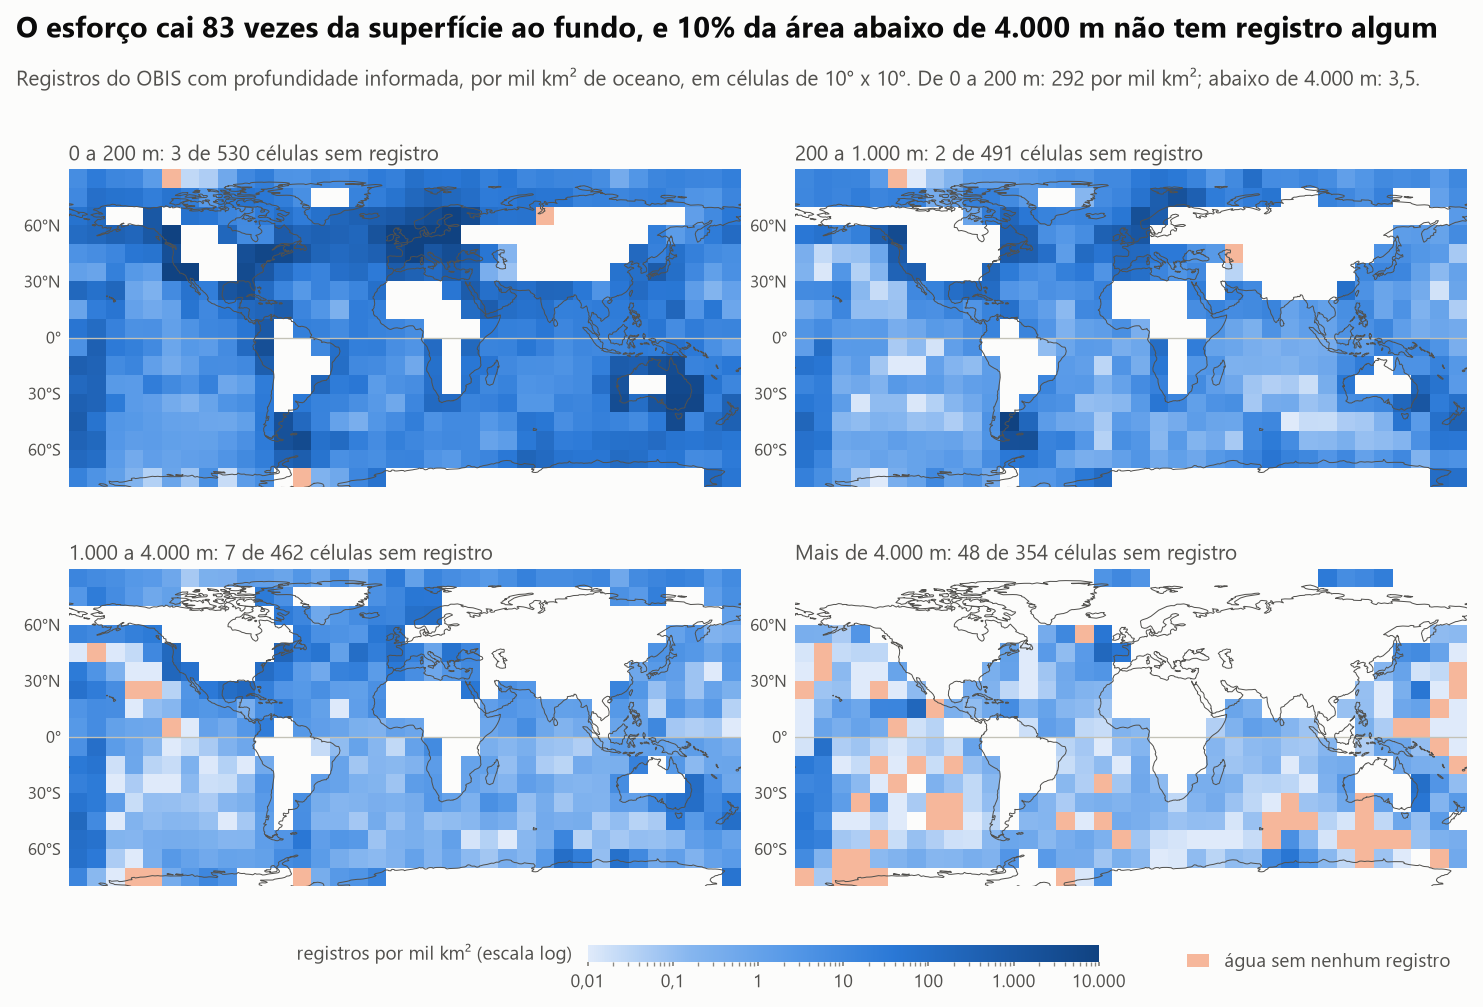

In [4]:
fig = graficos.mapa_do_esforco(unid, d["costa"], esforco); plt.show()

In [5]:
pd.Series(esforco["desigualdade_celulas"])

celulas                                          530,00
gini                                               0,90
fracao_da_area_com_metade_dos_registros            0,01
fracao_dos_registros_nos_10pct_da_area             0,87
fracao_dos_registros_na_metade_menos_amostrada     0,01
celulas_sem_registro                               0,00
dtype: float64

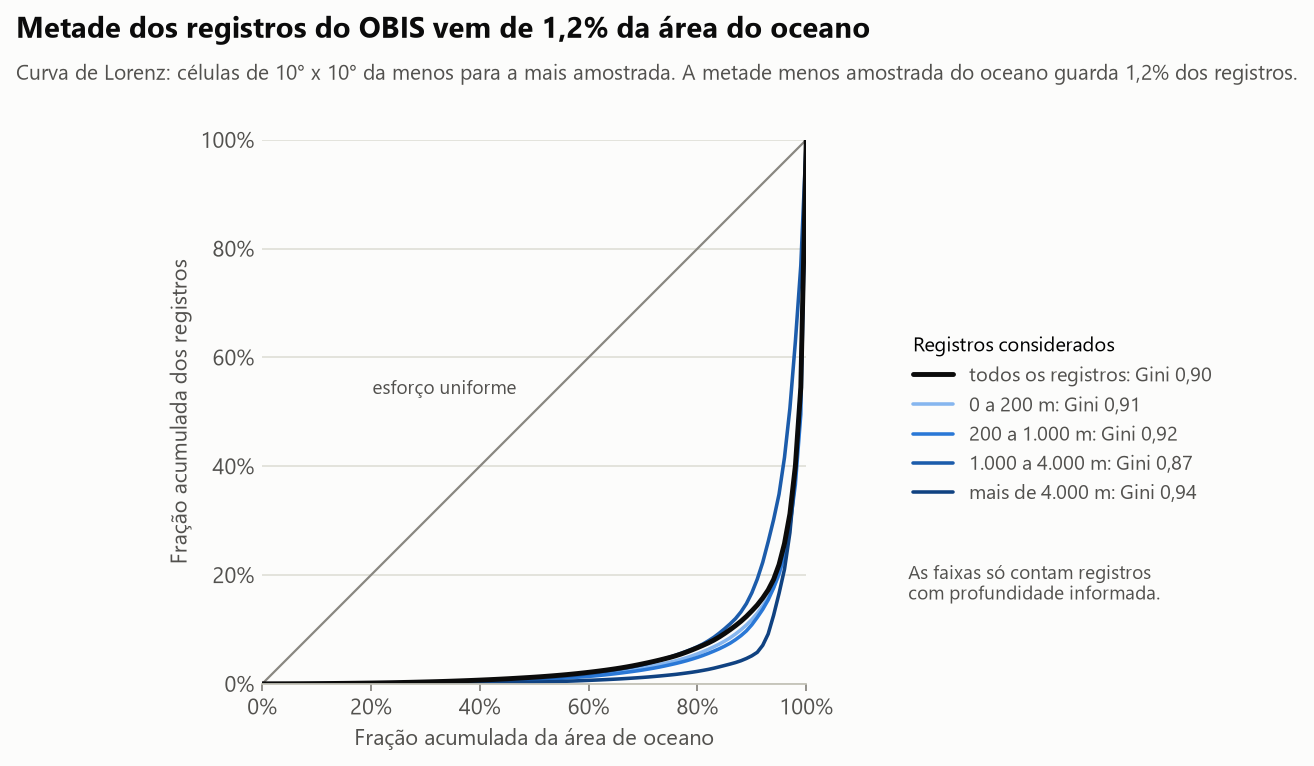

In [6]:
fig = graficos.lorenz(analise.curvas_de_lorenz(unid, d["celulas"]), esforco); plt.show()

## 2. Os estimadores numa unidade, passo a passo

Antes de aplicar a todas, uma unidade só. Os estimadores usam as espécies raras da amostra (as que têm um ou dois
registros) para estimar quantas ainda não apareceram.

In [7]:
aval = analise.estimar(unid, contagens, rng["estimar"])
exemplo = aval.sort_values("registros_especie").iloc[len(aval) // 2]
x = contagens[(exemplo["celula"], exemplo["faixa"])]
n, s, f1, f2 = riqueza.resumo(x)
print(exemplo["rotulo"], "|", dados.ROTULO_FAIXA[exemplo["faixa"]])
print(f"registros de espécie n = {n}; espécies observadas S = {s}; com 1 registro f1 = {f1}; com 2 registros f2 = {f2}")
print(f"Chao1 = S + (n-1)/n * f1^2 / (2*f2) = {riqueza.chao1(x):.0f}, intervalo de 95% {tuple(round(v) for v in riqueza.intervalo_chao1(x))}")
print(f"ACE = {riqueza.ace(x):.0f}; jackknife = {riqueza.jackknife1(x):.0f}")
print(f"Completude (S / Chao1) = {s / riqueza.chao1(x):.0%}")
print(f"Cobertura da amostra = {riqueza.cobertura(x):.1%} (a chance de o próximo registro ser de espécie já vista)")
print(f"Espécies novas esperadas nos próximos mil registros = {riqueza.novas_por_mil(x):.0f}")

70°S a 60°S, 170°W a 160°W | 0 a 200 m
registros de espécie n = 3290; espécies observadas S = 182; com 1 registro f1 = 54; com 2 registros f2 = 26
Chao1 = S + (n-1)/n * f1^2 / (2*f2) = 238, intervalo de 95% (210, 293)
ACE = 244; jackknife = 236
Completude (S / Chao1) = 76%
Cobertura da amostra = 98.4% (a chance de o próximo registro ser de espécie já vista)
Espécies novas esperadas nos próximos mil registros = 14


In [8]:
extra = np.array([0, 250, 500, 1000, 2000, 4000])
pd.DataFrame({"registros adicionais": extra, "riqueza esperada": riqueza.extrapolacao(x, extra),
              "cobertura esperada": [riqueza.cobertura_extrapolada(x, e) for e in extra]}).set_index("registros adicionais")

,riqueza esperada,cobertura esperada
registros adicionais,,
0,"182,00","0,98"
250,"185,96","0,98"
500,"189,63","0,99"
1000,"196,23","0,99"
2000,"206,84","0,99"
4000,"220,68","0,99"


## 3. Os estimadores acertam? Comunidades simuladas de riqueza conhecida

Duas comunidades com 2.000 espécies: uma com abundâncias moderadamente desiguais e outra com muitas espécies
raras. A tabela mostra a estimativa dividida pela riqueza verdadeira e, na última coluna, a razão entre as
espécies novas previstas para os próximos mil registros e as que de fato viriam.

In [9]:
sim = analise.simular(rng["simular"])
sim.set_index(["comunidade", "registros"])[["observada_sobre_real", "chao1_sobre_real", "ace_sobre_real",
    "jackknife1_sobre_real", "intervalo_chao1_contem_a_verdade", "cobertura_real", "cobertura_estimada", "previstas_sobre_verdadeiras"]]

observada_sobre_real  chao1_sobre_real  ace_sobre_real  jackknife1_sobre_real  intervalo_chao1_contem_a_verdade  cobertura_real  cobertura_estimada  \
comunidade   registros                                                                                                                                                        
equilibrada  100                        0,05              0,59            0,58                   0,09                              0,58            0,12                0,11   
             300                        0,13              0,56            0,56                   0,24                              0,13            0,27                0,27   
             1000                       0,32              0,68            0,74                   0,54                              0,00            0,57                0,57   
             3000                       0,60              0,84            0,88                   0,86                              0,02            0,82                0,82   
             10000                      0,87              0,96            0,96                   1,03                              0,12            0,97                0,97   
             30000                      0,97              0,99            0,99                   1,02                              0,83            1,00                1,00   
             100000                     1,00              1,00            1,00                   1,00                              0,88            1,00                1,00   
muitas raras 100                        0,03              0,11            0,10                   0,05                              0,02            0,55                0,54   
             300                        0,07              0,16            0,17                   0,11                              0,00            0,71                0,72   
             1000                       0,14              0,26            0,28                   0,21                              0,00            0,85                0,85   
             3000                       0,24              0,39            0,39                   0,34                              0,00            0,93                0,93   
             10000                      0,39              0,55            0,54                   0,52                              0,00            0,97                0,97   
             30000                      0,54              0,69            0,69                   0,69                              0,00            0,99                0,99   
             100000                     0,71              0,82            0,81                   0,84                              0,00            1,00                1,00   

                        previstas_sobre_verdadeiras  
comunidade   registros                               
equilibrada  100                               0,95  
             300                               0,96  
             1000                              0,97  
             3000                              0,98  
             10000                             1,01  
             30000                             0,99  
             100000                            0,99  
muitas raras 100                               0,61  
             300                               0,79  
             1000                              0,96  
             3000                              1,00  
             10000                             1,01  
             30000                             0,99  
             100000                            1,00

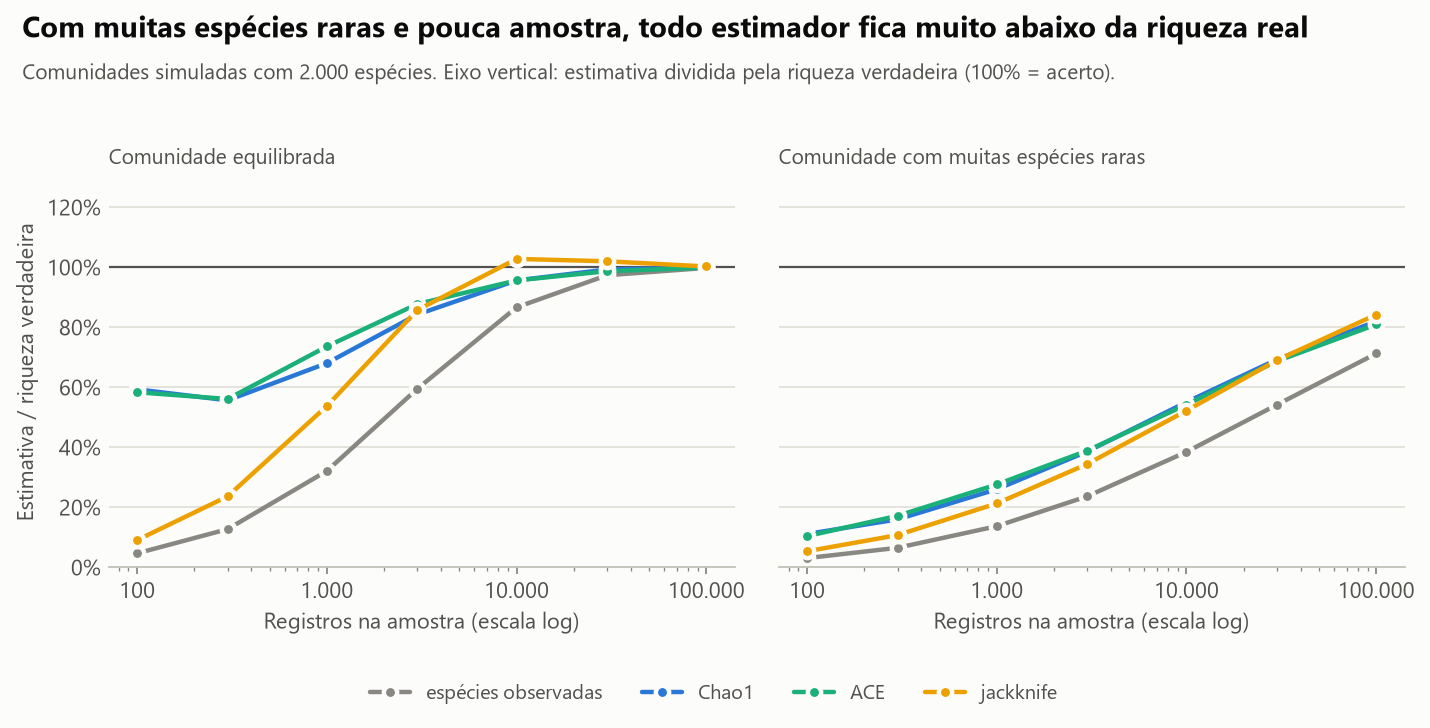

In [10]:
fig = graficos.simulacao(sim); plt.show()

Leitura: a riqueza total é subestimada sempre que há muitas espécies raras e pouca amostra (o Chao1 é um limite
inferior, e o intervalo dele quase nunca contém a verdade nesses casos). Já a previsão de curto prazo, quantas
espécies novas nos próximos mil registros, fica perto do valor verdadeiro a partir de mil registros. É por isso
que a pergunta de decisão do estudo é a de curto prazo, e não "quantas espécies existem na célula". Na simulação
os registros são sorteados ao acaso; no OBIS não são, e a seção 5 mede a diferença.

## 4. Completude e retorno esperado em todas as unidades avaliáveis

In [11]:
pd.Series({k: v for k, v in analise.resumo_da_completude(aval).items() if k != "por_faixa"})

unidades                        960,00
completude_mediana                0,72
completude_p10                    0,56
completude_p90                    0,85
unidades_acima_de_80pct         213,00
unidades_abaixo_de_50pct         57,00
cobertura_mediana                 0,97
razao_mediana_ace_chao1           1,01
razao_mediana_jackknife_chao1     0,98
novas_por_mil_mediana            24,21
novas_por_mil_p90               105,03
dtype: float64

In [12]:
colunas = ["posto", "rotulo", "faixa", "registros_especie", "especies", "completude", "completude_inf", "completude_sup",
           "novas_por_mil", "novas_por_mil_inf", "novas_por_mil_sup", "posto_ace", "posto_menos_registros",
           "posto_mais_especies", "fracao_maior_conjunto"]
aval.head(analise.TOPO)[colunas].set_index("posto")

,rotulo,faixa,registros_especie,especies,completude,completude_inf,completude_sup,novas_por_mil,novas_por_mil_inf,novas_por_mil_sup,posto_ace,posto_menos_registros,posto_mais_especies,fracao_maior_conjunto
posto,,,,,,,,,,,,,,
1,"10°S a 0°, 30°E a 40°E",200-1000,653,518,"0,20","0,15","0,26","580,90","523,38","638,42",1,75,363,"0,69"
2,"10°N a 20°N, 70°E a 80°E",200-1000,3222,1575,"0,16","0,14","0,20","376,05","359,29","392,82",2,474,110,"0,37"
3,"0° a 10°N, 70°E a 80°E",200-1000,3179,1493,"0,21","0,17","0,25","349,87","332,04","367,70",3,470,122,"0,20"
4,"10°N a 20°N, 120°E a 130°E",1000-4000,545,340,"0,41","0,33","0,50","288,36","242,77","333,95",4,20,510,"0,36"
5,"0° a 10°N, 70°E a 80°E",1000-4000,638,323,"0,35","0,27","0,45","269,46","225,34","313,57",5,68,521,"0,18"
6,"10°S a 0°, 110°E a 120°E",200-1000,894,478,"0,49","0,41","0,57","243,49","208,59","278,38",6,154,388,"0,50"
7,"30°S a 20°S, 40°W a 30°W",1000-4000,615,324,"0,43","0,34","0,53","240,14","197,45","282,82",7,55,520,"0,18"
8,"10°S a 0°, 30°E a 40°E",0-200,1525,659,"0,53","0,47","0,59","218,24","197,94","238,54",9,290,299,"0,65"
9,"70°S a 60°S, 70°W a 60°W",1000-4000,726,412,"0,55","0,47","0,63","216,47","183,20","249,74",8,114,436,"0,27"


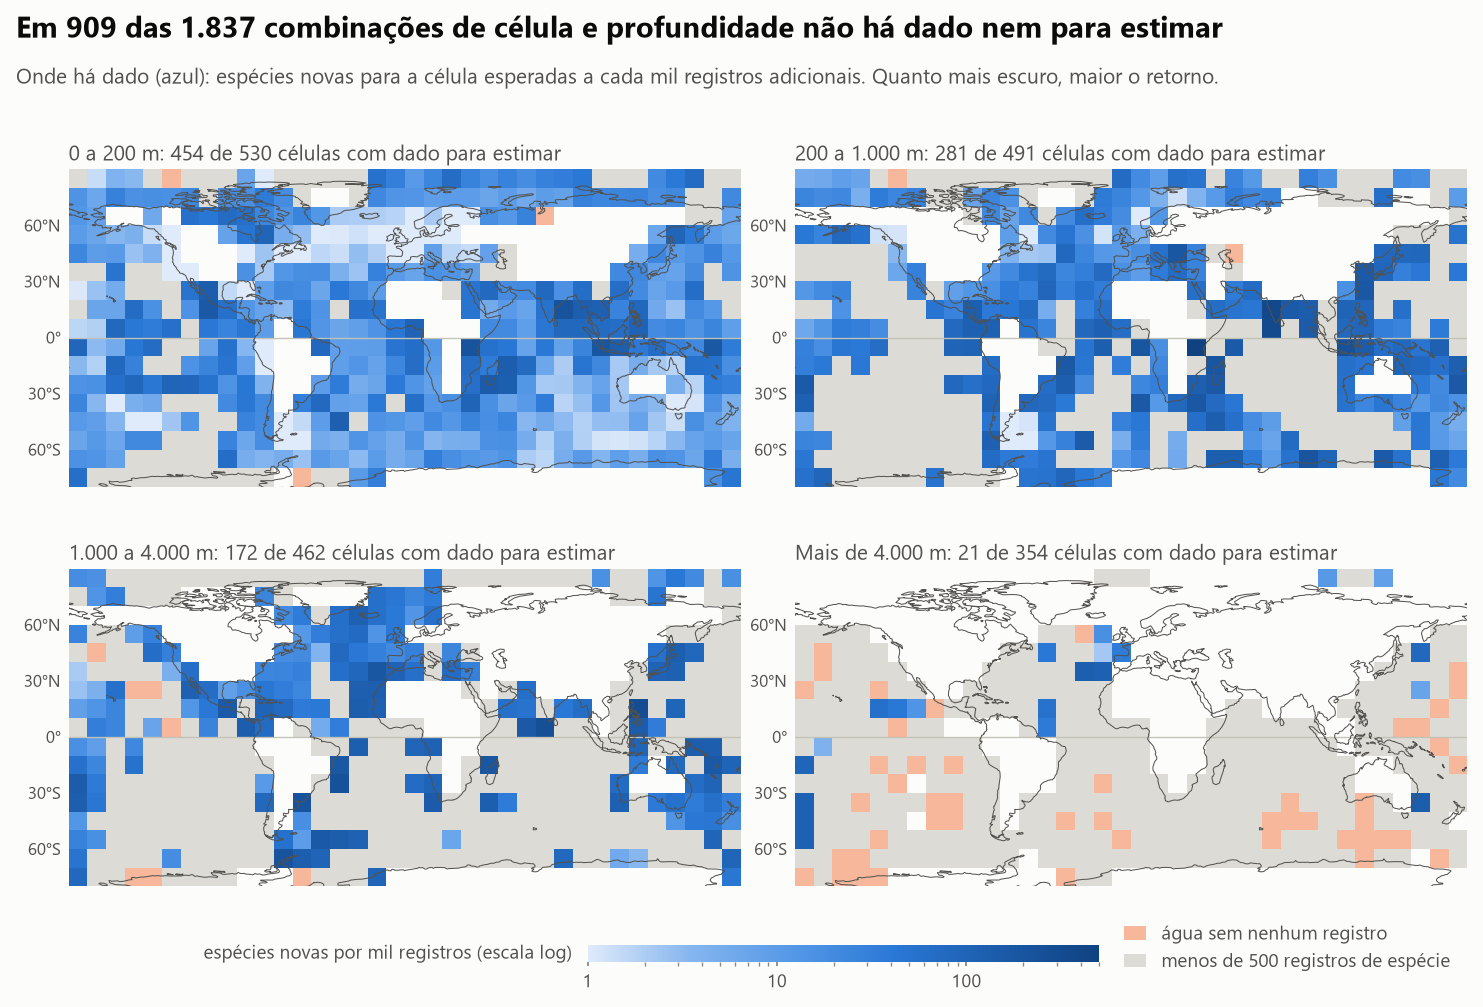

In [13]:
fig = graficos.mapa_de_prioridades(unid, aval, d["costa"], esforco); plt.show()

### Quanto o ranking muda entre estimadores e contra as linhas de base

In [14]:
rankings = analise.comparar_rankings(aval)
print({k: v for k, v in rankings.items() if k != "contra_o_retorno_chao1"})
pd.DataFrame(rankings["contra_o_retorno_chao1"]).T

{'unidades': 960, 'topo': 20, 'spearman_menos_registros_x_mais_especies': -0.7410042344946256, 'em_comum_menos_registros_x_mais_especies': 0, 'no_topo_das_tres': 0, 'maior_troca_de_posto_chao1_ace': 234, 'mediana_troca_de_posto_chao1_ace': 5.0, 'spearman_retorno_x_registros': -0.600724259026827, 'spearman_retorno_x_completude': -0.5882650832954461}


,spearman,em_comum_no_topo
retorno (ACE),"1,00","17,00"
retorno (Good-Turing),"0,98","14,00"
menos registros,"0,60","1,00"
mais espécies registradas,"-0,02","0,00"


## 5. Validação no tempo: o ranking de 2010 previu o que apareceu depois?

Para cada unidade com pelo menos 500 registros de espécie até 2010 e mil depois: a previsão usa só os registros
até 2010; o realizado é quantas das espécies que só apareceram depois estariam em mil registros sorteados entre
os posteriores. As cinco regras são comparadas pelo mesmo alvo.

In [15]:
val = analise.tabela_de_validacao(unid, dados.frequencias_da_unidade(d["frequencias"], "ate_corte"),
                                  dados.frequencias_da_unidade(d["frequencias"], "novas_depois_corte"), rng["validar"])
avaliacao = analise.avaliar_validacao(val, rng["avaliar"])
pd.DataFrame(avaliacao["regras"]).T

,spearman,spearman_inf,spearman_sup,realizado_medio_no_topo,acertos_no_topo,vantagem_do_retorno_chao1,vantagem_inf,vantagem_sup
retorno (Chao1),"0,49","0,39","0,58","197,25","7,00",NaN,NaN,NaN
retorno (ACE),"0,49","0,39","0,58","157,36","6,00","0,00","-0,00","0,00"
retorno (Good-Turing),"0,49","0,40","0,58","160,60","5,00","-0,00","-0,02","0,01"
menos registros,"0,35","0,24","0,46","113,79","3,00","0,14","0,06","0,21"
mais espécies registradas,"0,01","-0,10","0,13","63,57","2,00","0,48","0,31","0,63"


In [16]:
print("Calibração por mil registros:"); print(pd.Series(avaliacao["calibracao_por_mil"]))
print("\nNo esforço real de cada unidade:"); print(pd.Series(avaliacao["calibracao_no_total"]))

Calibração por mil registros:
previsto_mediano                       10,07
realizado_mediano                      40,19
razao_mediana_realizado_previsto        3,38
razao_p25                               1,29
razao_p75                               8,21
fracao_dentro_do_intervalo              0,06
fracao_realizado_acima_do_intervalo     0,78
fracao_realizado_abaixo_do_intervalo    0,16
fracao_dentro_de_um_fator_2             0,29
dtype: float64

No esforço real de cada unidade:
unidades_dentro_do_dobro           245,00
razao_mediana_todas                  1,80
razao_mediana_dentro_do_dobro        2,01
razao_mediana_alem_do_dobro          1,19
novas_realizadas_total          69.739,00
novas_previstas_total           42.938,35
dtype: float64


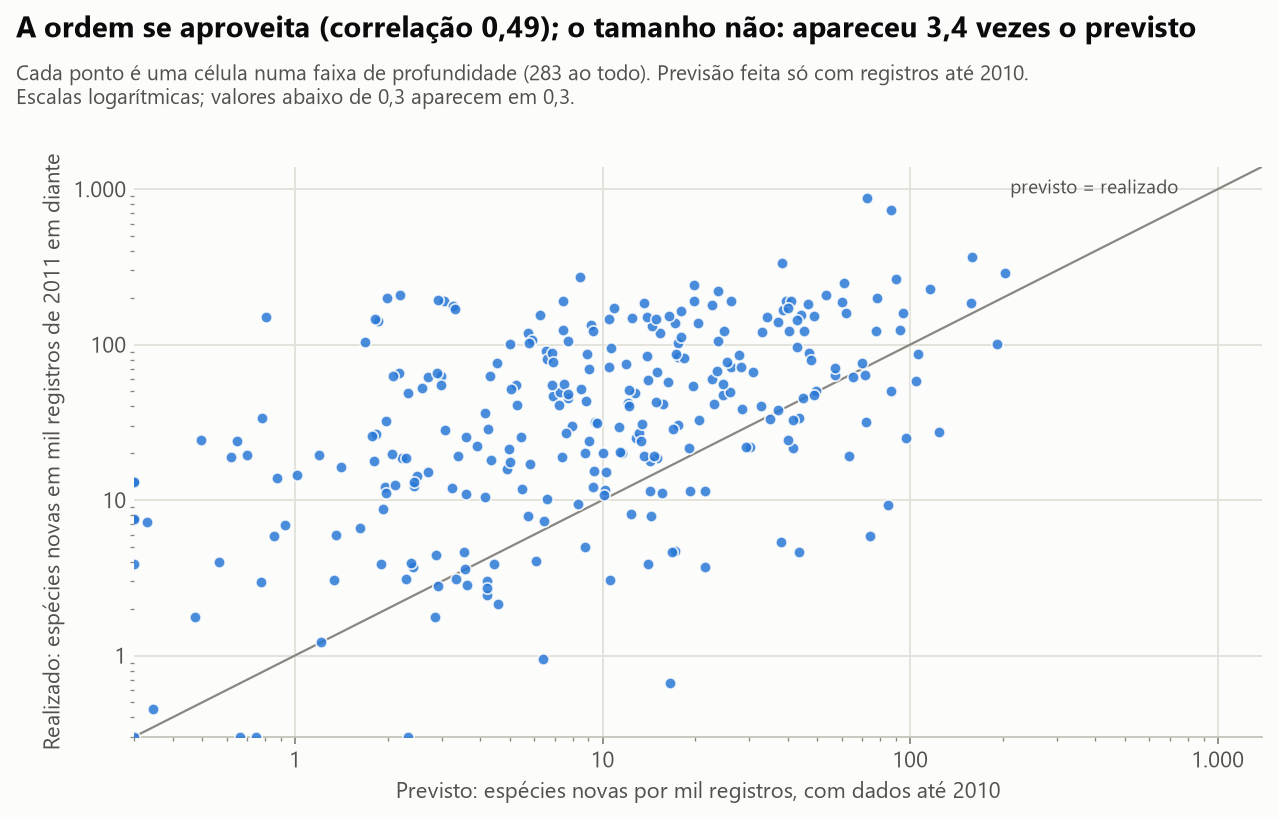

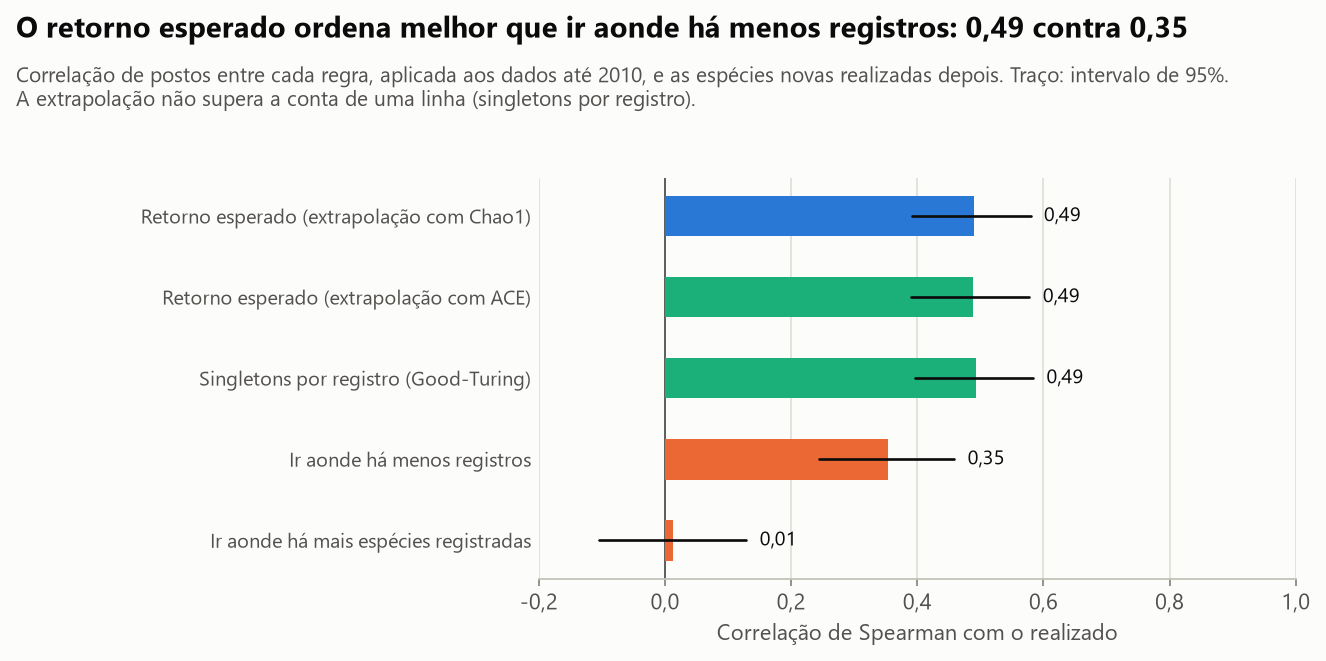

In [17]:
fig = graficos.previsto_x_realizado(val, avaliacao); plt.show()
fig = graficos.rankings_na_validacao(avaliacao); plt.show()

## 6. Vieses medidos

In [18]:
v = analise.vieses(unid, aval)
print(pd.Series(v["conjunto_dominante"])); print(); print(pd.Series({k: w for k, w in v["identificacao"].items() if not isinstance(w, dict)}))
pd.Series(v["identificacao"]["fracao_acima_de_especie_por_faixa"]).rename("fração dos registros acima de espécie")

limiar                               0,50
fracao_mediana_do_maior_conjunto     0,48
unidades_avaliaveis_dominadas      453,00
fracao_das_avaliaveis_dominadas      0,47
dominadas_no_topo                    7,00
spearman_completude_x_dominancia    -0,04
spearman_retorno_x_dominancia       -0,18
completude_mediana_dominadas         0,71
completude_mediana_demais            0,72
dtype: float64

fracao_acima_de_especie                                       0,38
fracao_so_genero                                              0,11
unidades_que_seriam_avaliaveis_com_os_registros_de_genero   107,00
spearman_retorno_x_fracao_acima_de_especie                    0,14
dtype: float64


0-200       0,37
1000-4000   0,72
200-1000    0,35
4000+       0,74
Name: fração dos registros acima de espécie, dtype: float64

## 7. O que levar daqui

Os números finais e a leitura estão no `README.md`, e saem de `reports/resultados.json`. As duas tabelas para
reuso estão em `reports/celulas_prioritarias.csv` (unidades avaliáveis, na ordem do retorno esperado) e
`reports/lacunas_sem_inventario.csv` (unidades sem registro ou com amostra insuficiente).